In [5]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from shapely.geometry import Point
import geopandas
import matplotlib.pyplot as plt
import json

In [2]:
paradisec = 'https://catalog.paradisec.org.au/collections/search'

In [3]:
html_content = requests.get(paradisec).content

soup = BeautifulSoup(html_content, 'html.parser')

In [8]:
a_tags = soup.find_all('a')

In [10]:
paradisec_languages = [a_tag.text.strip() for a_tag in a_tags]

In [12]:
len(paradisec_languages)

336

In [13]:
glottolog_data = pd.read_csv('languages_and_dialects_geo.csv')

In [14]:
df_filtered = glottolog_data[glottolog_data['name'].isin(paradisec_languages)]

In [15]:
df_filtered

,glottocode,name,isocodes,level,macroarea,latitude,longitude
63,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
503,amar1273,Amarasi,aaz,language,Papunesia,-10.21751,123.96373
647,anei1239,Aneityum,aty,language,Papunesia,-20.18640,169.82500
678,ango1255,Angoram,aog,language,Papunesia,-4.07758,144.02800
917,aros1241,Arosi,aia,language,Papunesia,-10.24410,161.43200
...,...,...,...,...,...,...,...
20301,vari1239,Varisi,vrs,language,Papunesia,-6.83443,156.65500
20495,nucl1620,Wahgi,wgi,language,Papunesia,-6.11629,144.66500
20570,walm1242,Walmajarri,NaN,dialect,Australia,NaN,NaN
20697,warl1254,Warlpiri,wbp,language,Australia,-20.10080,131.05000


In [16]:
points = df_filtered.apply(lambda r: Point(r.longitude, r.latitude), axis=1)
gdb = geopandas.GeoDataFrame(df_filtered.assign(geometry=points), \
                        crs={'init' :'epsg:4326'})
xys = gdb['geometry'].apply(lambda pt: pd.Series({'x': pt.x, 'y': pt.y}))
gdb['x'] = xys['x']
gdb['y'] = xys['y']

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [17]:
worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_55217/867032107.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))


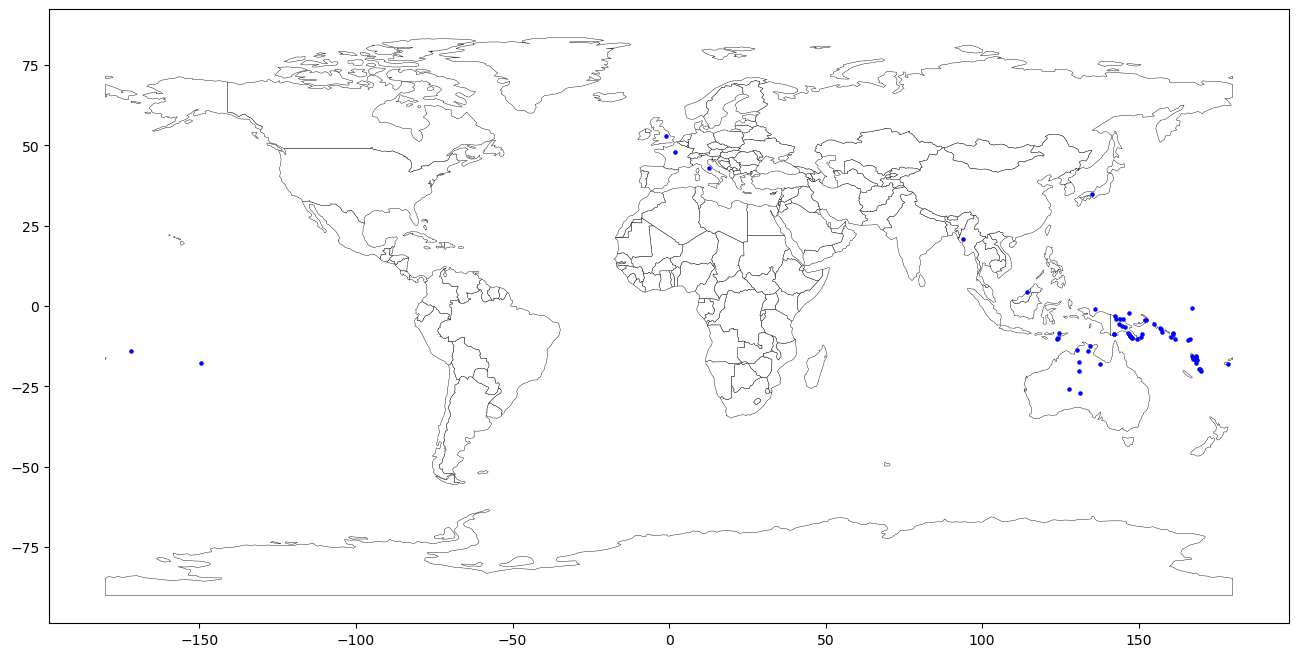

In [18]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

# Size extraction

In [6]:
graphql_query = """{
  items(limit: 100, page: 2) {
    total
    next_page
    results {
      full_identifier
      title
      description
      dialect
      language
      region
      originated_on
      essences_count
      essences {
        id   
        filename
        duration
        bitrate:bitrate
        samplerate
        itemId
        mimetype
        updatedAt
        fps
      }
      originated_on_narrative
      collection {
        identifier
        title
      }
      collector {
        first_name
        last_name
        country
      }
      university {
        name
        party_identifier
      }
      discourse_type {
        name
      }
      data_types {
        name
      }
      data_categories {
        name
      }
      countries {
        name
        code
      }
      subject_languages {
        name
        code
      }
      content_languages {
        name
        code
      }
      access_class
      access_narrative
      citation
      ingest_notes
      original_media
      permalink
      doi
    }
  }
}"""



In [7]:
headers = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10.15; rv:124.0) Gecko/20100101 Firefox/124.0",
    "Accept": "*/*",
    "Accept-Language": "en-GB,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Referer": "https://catalog.paradisec.org.au/graphiql",
    "Content-Type": "application/json",
    "X-CSRF-Token": "WMRdCmarai5DfoZrbM1MdTJtYh-7kx73DPKGr5cgNJn9R9JahgbhsScC4IG4UteTSgmpp-x2AtySU2w1pesaqA",
    "Origin": "https://catalog.paradisec.org.au",
    "Connection": "keep-alive",
    "Cookie": "_ga_X7RT9Y7NXS=GS1.1.1711475412.8.1.1711475953.0.0.0; _ga=GA1.3.1409180406.1711383017; _gid=GA1.3.1117965470.1711383018; _nabu_session=Na1v8PMml3%2BaGb4qjxRi%2F4WaI4jcFeTm5ocIlTaaHagMuZj6ht4mjqUHJ4IFdxyiT3yxy54umIUjL2b9P0UKThudJJEgSdtNXBH4SRcrepdPtCvWoCnSkmsKuk8v7gxcRIMyztcZgIyeKFUxtuMFEU20UIJJSqxucf%2FsFy5W2%2BXOoYHRhT8fCmbSabIyWkmcVkxJyldWcEMWGS4RSNXIAdV3KnEUjVztNjMuNSqFkDj0LJ17q0IDWsUEI7FKiuZ%2BRMobigJbxBr1h3i6Y6oY6Rst0GxzBB%2BAkAfkM2z2K%2FmKSFPql11%2Bk2xkpLwmOPU7yaJfypxMWTyO0EOrVz9UY2cEez90LduZxpB2QZuV7PZFIohwFmpG0FoMUvhpULJpPOn3GPGbaqQA1b23IKKHTFvPL2YAnsT%2Bf5JqP49rQTFyYidzLDTV6giLFLQzyPxJnsMvrv%2B2cqKRCHspqkCtYmNzLAsCCFksMFgLJYHKKkDv%2FGII3B9qFy0LuxDePyUa5WQNqkve6rz1l%2BskpXHOjr2Mj8KY7oROuvay61U139mcGznNEAA8scjdNH6WY%2Bi3Cf4V%2BNLR2lnWDJGObOwP2pU%2FR5W7KYUWK9UnacP7VJN9%2BMG%2FFCMIXjH9MWP2X87wYOatlGaaF2Y4lRzS6vTlFE8zY74LUH9Skwdl669INJfuZcvocxYJ7DA4F6mWyAkirEl%2F6aq%2F2b9E--QlwX8pBq%2FxmRznVV--Z4LJfJGbMFTJNgy%2F5Mjc8w%3D%3D",
    "Sec-Fetch-Dest": "empty",
    "Sec-Fetch-Mode": "cors",
    "Sec-Fetch-Site": "same-origin",
    "TE": "trailers"
}


In [17]:
url = 'https://catalog.paradisec.org.au/graphiql'

In [18]:

response = requests.post(url=url, json=graphql_query, headers=headers)

In [19]:
response

<Response [404]>

In [20]:
tr = response.json()

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [98]:
def run_query(query): # A simple function to use requests.post to make the API call. Note the json= section.
    request = requests.post('https://catalog.paradisec.org.au/graphiql', json={'query': query})
    if request.status_code == 200:
        return request.json()
    else:
        raise Exception("Query failed to run by returning code of {}. {}".format(request.status_code, query))

In [102]:
request = requests.post('https://catalog.paradisec.org.au/graphiql', json={'query': graphql_query})

In [103]:
request

<Response [404]>

In [99]:
result = run_query(graphql_query)

Exception: Query failed to run by returning code of 404. {
  items(limit: 100, page: 2) {
    total
    next_page
    results {
      full_identifier
      title
      description
      dialect
      language
      region
      originated_on
      essences_count
      essences {
        id   
        filename
        duration
        bitrate:bitrate
        samplerate
        itemId
        mimetype
        updatedAt
        fps
      }
      originated_on_narrative
      collection {
        identifier
        title
      }
      collector {
        first_name
        last_name
        country
      }
      university {
        name
        party_identifier
      }
      discourse_type {
        name
      }
      data_types {
        name
      }
      data_categories {
        name
      }
      countries {
        name
        code
      }
      subject_languages {
        name
        code
      }
      content_languages {
        name
        code
      }
      access_class
     

In [105]:
url = 'https://catalog.paradisec.org.au/graphiql'  # Replace 'example.com/graphql' with your actual GraphQL endpoint

# Define the query
query = {
    "query": """
        {
          items(limit: 10000, page: 5) {
            total
            next_page
            results {
              full_identifier
              title
              description
              dialect
              language
              region
              originated_on
              essences_count
              essences {
                id
                filename
                duration
                bitrate: bitrate
                samplerate
                itemId
                mimetype
                updatedAt
                fps
              }
              originated_on_narrative
              collection {
                identifier
                title
              }
              collector {
                first_name
                last_name
                country
              }
              countries {
                name
                code
              }
              subject_languages {
                name
                code
              }
              content_languages {
                name
                code
              }
            }
          }
        }
    """
}

# Send the HTTP request
response = requests.post(url, json=query)

In [106]:
response

<Response [404]>

In [70]:
tr

b'<!DOCTYPE html>\n<html data-turbo="false">\n<head>\n<script src="https://www.googletagmanager.com/gtag/js?id=UA-36256674-1" async="async"></script>\n<script>\n  window.dataLayer = window.dataLayer || [];\n  function gtag(){dataLayer.push(arguments);}\n  gtag(\'js\', new Date());\n  \n  gtag(\'config\', \'UA-36256674-1\');\n</script>\n<script>\n  const calendarImagePath = "/assets/calendar-d5c51e197c3a7c2bb8a45632329bd711834f398720665eb0d18dad6bad324262.png";\n</script>\n<title>Nabu - Home</title>\n<meta content="width=device-width,initial-scale=1" name="viewport">\n<meta content="reload" name="turbo-visit-control">\n<meta name="csrf-param" content="authenticity_token" />\n<meta name="csrf-token" content="NiuSkCb9cnqbjFH5N1KoIWx17VsrUSdv98mPlMVt_nzYgxHSIKuhXeNQbFNNofAGbRkwxxEdJnr1SjsOfXPlAw" />\n<link rel="stylesheet" href="/assets/application-f189b4affc5b147f8f8e8803765c189f66e289645f991bcdebb6045f1b7718b1.css" data-turbo-track="reload" />\n<script type="importmap" data-turbo-track="

In [62]:
type(graphql_query)

str

In [81]:
my_json = response.content.decode('utf8').replace("'", '"')

In [82]:
my_json

'type AccessCondition {\n  collections: [Collection]\n  items: [Item]\n  name: String\n}\n\ntype Agent {\n  role_name: String\n  user: Person\n  user_name: String\n}\n\ntype Boundary {\n  east_limit: Float!\n  north_limit: Float!\n  south_limit: Float!\n  west_limit: Float!\n}\n\ntype Collection {\n  access_class: String\n  access_narrative: String\n  boundaries: Boundary\n  citation: String\n  collector: Person\n  comments: String\n  complete: Boolean\n  content_languages: [Language]\n  countries: [Country]\n  description: String\n  doi: String\n  doi_xml: String\n  field_of_research: FieldOfResearch\n  grants: [Grant]\n  id: ID!\n  identifier: String!\n  media: String\n  metadata_source: String\n  operator: Person\n  orthographic_notes: String\n  permalink: String!\n  region: String\n  subject_languages: [Language]\n  tape_location: Boolean\n  title: String!\n  university: University\n}\n\ntype Country {\n  boundaries: [Boundary]\n  code: String!\n  id: ID!\n  languages: [Language]\n

In [83]:
data = json.loads(my_json)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)